# Exploratory Data Analysis (EDA)

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [46]:
df= pd.read_csv("../data/raw/AAPL_daily_compact.csv", 
                parse_dates=["Unnamed: 0"])
df=df.rename(columns={"Unnamed: 0": "Date"})
df=df.set_index("Date")
df.columns.name='AdjClose'
df.head()

AdjClose,Open,High,Low,Close,Volume
Date,,,,,
2025-08-06,205.630,215.38,205.59,213.25,108483103
2025-08-07,218.875,220.85,216.58,220.03,90224834
2025-08-08,220.830,231.00,219.25,229.35,113853967
2025-08-11,227.920,229.56,224.76,227.18,61806132
2025-08-12,228.005,230.80,227.07,229.65,55672301


<Axes: xlabel='Date'>

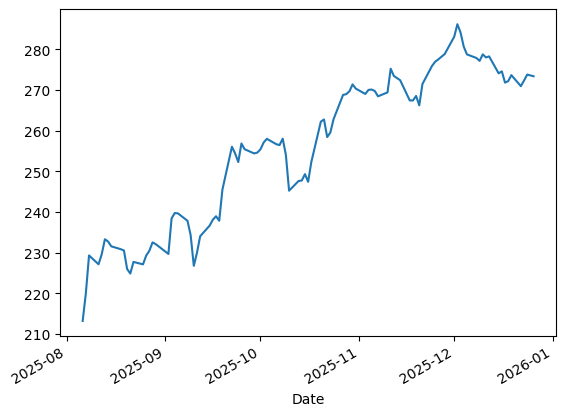

In [47]:
df["Close"].plot()

In [48]:
df["Return"]=df["Close"].pct_change()

In [49]:
df["MA_5"]=df["Close"].rolling(5).mean()

In [50]:
df.resample("W").mean()

AdjClose,Open,High,Low,Close,Volume,Return,MA_5
Date,,,,,,,
2025-08-10,215.111667,222.410000,213.806667,220.876667,1.041873e+08,0.037076,NaN
2025-08-17,231.010000,232.952000,228.489000,230.906000,5.906238e+07,0.001993,228.2910
2025-08-24,229.079000,230.414000,226.884080,228.024000,3.844834e+07,-0.003276,230.1316
2025-08-31,229.058000,231.296000,227.977000,230.332000,3.886218e+07,0.003830,228.4036
2025-09-07,236.226250,237.729975,234.140025,236.915000,5.313930e+07,0.008196,233.5035
2025-09-14,232.916000,235.262100,230.264000,232.624000,6.095740e+07,-0.004560,235.4424
2025-09-21,238.868000,241.402000,237.188840,239.444000,7.212391e+07,0.009655,235.5452
2025-09-28,253.339000,256.898000,251.646400,255.030000,6.187493e+07,0.008181,249.4408
2025-10-05,255.139000,257.425800,253.830000,255.932000,4.366635e+07,0.002002,255.2320


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 100 entries, 2025-08-06 to 2025-12-26
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    100 non-null    float64
 1   High    100 non-null    float64
 2   Low     100 non-null    float64
 3   Close   100 non-null    float64
 4   Volume  100 non-null    int64  
 5   Return  99 non-null     float64
 6   MA_5    96 non-null     float64
dtypes: float64(6), int64(1)
memory usage: 6.2 KB


In [52]:
df.isna().sum()

AdjClose
Open      0
High      0
Low       0
Close     0
Volume    0
Return    1
MA_5      4
dtype: int64

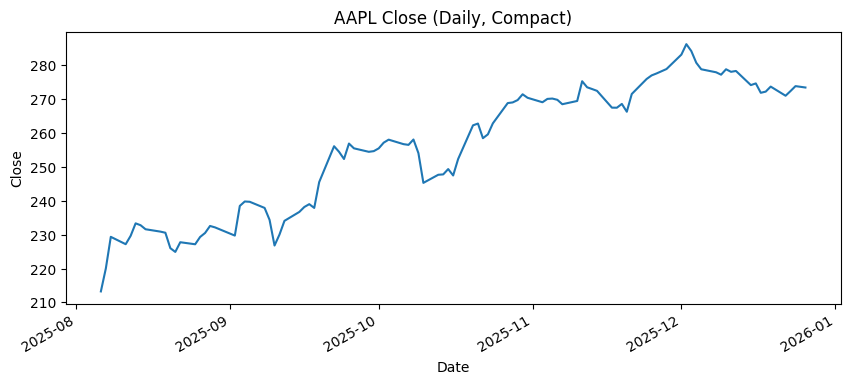

In [53]:
df["Close"].plot(figsize=(10,4), title="AAPL Close (Daily, Compact)")
plt.xlabel("Date")
plt.ylabel("Close")
plt.show()

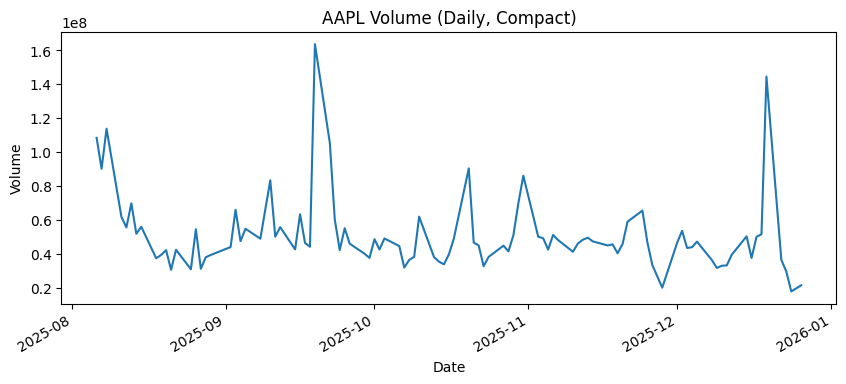

In [54]:
df["Volume"].plot(figsize=(10,4), title="AAPL Volume (Daily, Compact)")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.show()

In [55]:
df["Return"]=df["Close"].pct_change()
df[["Close","Return"]]. head(10)

AdjClose,Close,Return
Date,,
2025-08-06,213.25,NaN
2025-08-07,220.03,0.031794
2025-08-08,229.35,0.042358
2025-08-11,227.18,-0.009462
2025-08-12,229.65,0.010872
2025-08-13,233.33,0.016024
2025-08-14,232.78,-0.002357
2025-08-15,231.59,-0.005112
2025-08-18,230.89,-0.003023


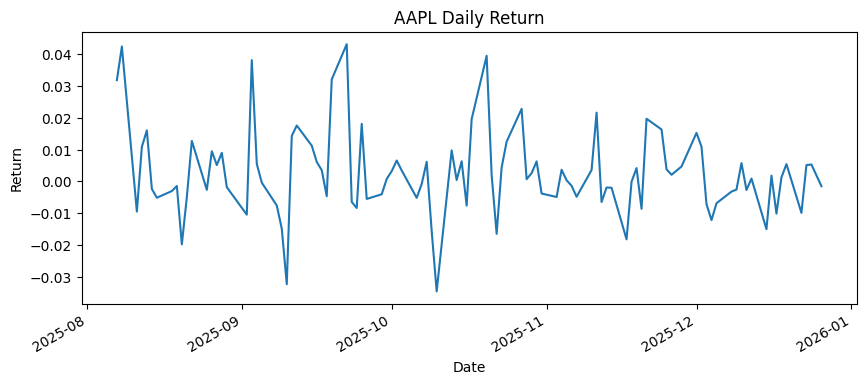

In [56]:
df["Return"].plot(figsize=(10,4), title="AAPL Daily Return")
plt.xlabel("Date")
plt.ylabel("Return")
plt.show()

In [57]:
df["MA_5"]=df["Close"].rolling(5).mean()
df["STD_5"]=df["Close"].rolling(5).std()
df[["Close","MA_5","STD_5"]].tail(10)

AdjClose,Close,MA_5,STD_5
Date,,,
2025-12-12,278.28,278.032,0.584611
2025-12-15,274.11,277.276,1.862211
2025-12-16,274.61,276.762,2.216342
2025-12-17,271.84,275.374,2.746348
2025-12-18,272.19,274.206,2.570609
2025-12-19,273.67,273.284,1.211561
2025-12-22,270.97,272.656,1.463892
2025-12-23,272.36,272.206,0.978381
2025-12-24,273.81,272.600,1.171708


In [58]:
weekly=df.resample("W").agg({"Close":"last", "Volume":sum})
weekly.head()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22188\3303139690.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  weekly=df.resample("W").agg({"Close":"last", "Volume":sum})


AdjClose,Close,Volume
Date,,
2025-08-10,229.35,312561904
2025-08-17,231.59,295311911
2025-08-24,227.76,192241677
2025-08-31,232.14,194310890
2025-09-07,239.69,212557180


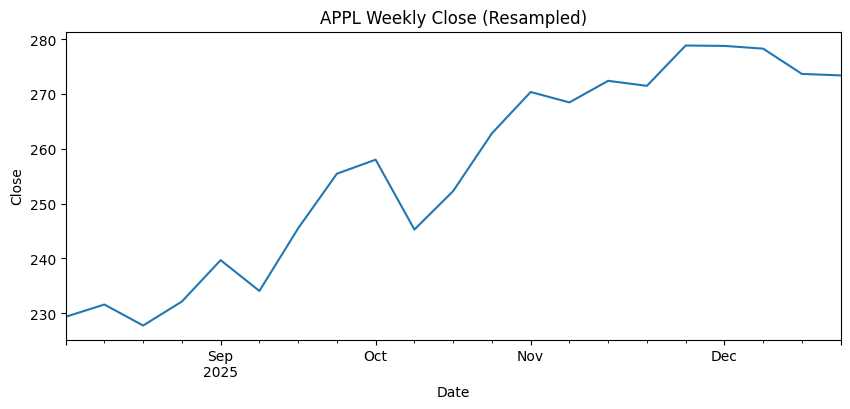

In [59]:
weekly["Close"].plot(figsize=(10,4), title="APPL Weekly Close (Resampled)")
plt.xlabel("Date")
plt.ylabel("Close")
plt.show()

# Exploratory Data Analysis (EDA)

This notebook performs exploratory data analysis on historical stock price data
to understand data quality, distributions, trends, and prepare features
for time-series forecasting models.


In [60]:
df_yahoo = pd.read_csv("../data/raw/AAPL_daily_10y_yahoo.csv")
df_yahoo.columns


Index(['Price', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')

In [61]:
df_yahoo=pd.read_csv( "../data/raw/AAPL_daily_10y_yahoo.csv", 
               parse_dates=[0], header=[0,1], index_col=0)
df_yahoo.columns=df_yahoo.columns.get_level_values(0).str.strip()
df_yahoo.index.name=("Date")
df_yahoo.columns.name="AdjClose"
df_yahoo.head()
print("Close df range:", df_yahoo.index.min(), df_yahoo.index.max())


Close df range: 2015-01-02 00:00:00 2025-12-26 00:00:00


In [62]:
df_yahoo.info()

print("Close df range:", df_yahoo.index.min(), df_yahoo.index.max())


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2763 entries, 2015-01-02 to 2025-12-26
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2763 non-null   float64
 1   High    2763 non-null   float64
 2   Low     2763 non-null   float64
 3   Close   2763 non-null   float64
 4   Volume  2763 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 129.5 KB
Close df range: 2015-01-02 00:00:00 2025-12-26 00:00:00


In [63]:
df_yahoo.isna().sum()
print("Close df range:", df_yahoo.index.min(), df_yahoo.index.max())

Close df range: 2015-01-02 00:00:00 2025-12-26 00:00:00


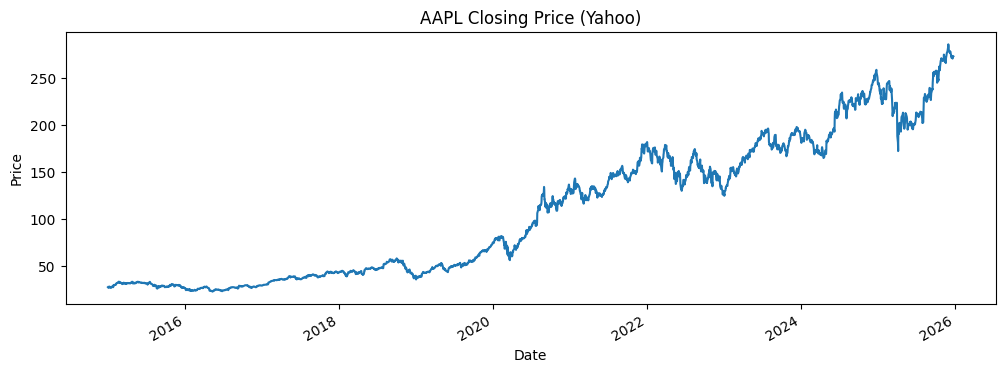

Close df range: 2015-01-02 00:00:00 2025-12-26 00:00:00


In [64]:
df_yahoo["Close"].plot(figsize=(12,4))   #The closing price of AAPL exhibits a 
#pronounced long-term upward trend with short-term fluctuations.
#  This behavior indicates a non-stationary time series, as both the mean and variance change over time.
plt.title("AAPL Closing Price (Yahoo)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.show()
print("Close df range:", df_yahoo.index.min(), df_yahoo.index.max())

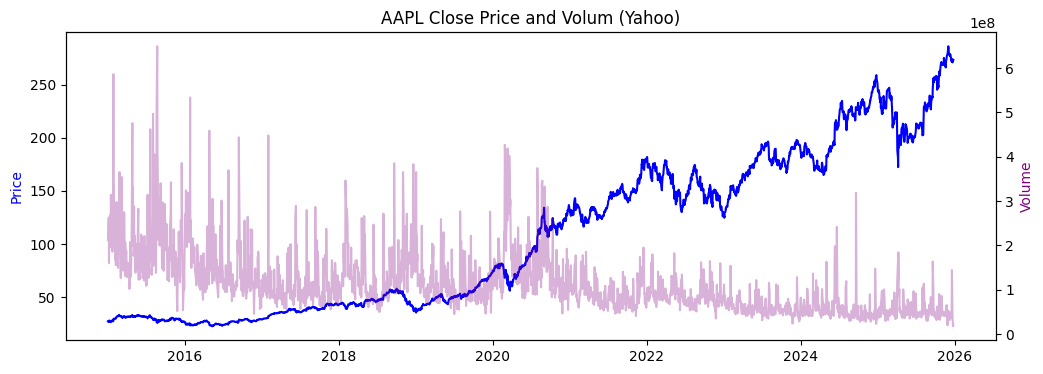

Close df range: 2015-01-02 00:00:00 2025-12-26 00:00:00


In [65]:
#The joint visualization of price and trading volume shows that volume 
# exhibits significant spikes over time, often coinciding with periods of 
# increased price fluctuations. However, high trading volume does not necessarily imply a 
# directional price movement
fig, ax1= plt.subplots(figsize=(12,4))
ax1.plot(df_yahoo.index, df_yahoo["Close"], color= "blue")
ax1.set_ylabel("Price", color="blue")
ax1.set_title("AAPL Close Price and Volum (Yahoo)")
ax2=ax1.twinx()
ax2.plot(df_yahoo.index, df_yahoo["Volume"], color= 'purple', alpha=0.3)
ax2.set_ylabel("Volume", color= "purple")
plt.show()
print("Close df range:", df_yahoo.index.min(), df_yahoo.index.max())

In [66]:
df_yahoo.index.min(), df_yahoo.index.max()

(Timestamp('2015-01-02 00:00:00'), Timestamp('2025-12-26 00:00:00'))

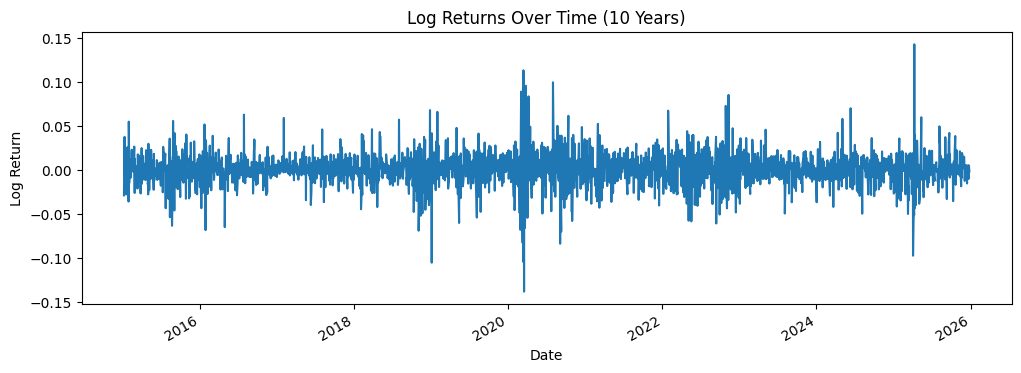

Close df range: 2015-01-05 00:00:00 2025-12-26 00:00:00


In [67]:
df_yahoo["Return"]= df_yahoo["Close"].pct_change()
df_yahoo["LogReturn"]= np.log(df_yahoo["Close"]/df_yahoo["Close"].shift(1))
df_yahoo=df_yahoo.dropna()
df_yahoo["LogReturn"].plot(figsize=(12,4))
plt.title("Log Returns Over Time (10 Years)")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()
print("Close df range:", df_yahoo.index.min(), df_yahoo.index.max())

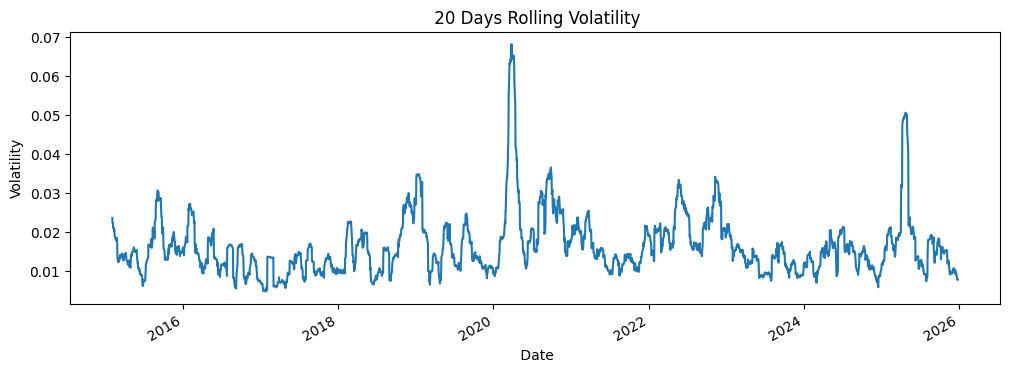

In [68]:
df_yahoo["Vol_20"]=df_yahoo["LogReturn"].rolling(20).std()
df_yahoo["Vol_20"].plot(figsize=(12,4))
plt.title(" 20 Days Rolling Volatility")
plt.xlabel(" Date")
plt.ylabel("Volatility")
plt.show()